Integrante: Laura Viviana Ospina Parra

Nombre del portafolio:

Fecha:

In [1]:
# 1. Instalar librerías e importar herramientas

!pip install yfinance -q

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
from scipy import stats
from scipy.stats import norm

# Formato de visualización
pd.options.display.float_format = "{:.4f}".format
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

print("Librerías cargadas ✔")

Librerías cargadas ✔


In [2]:
# 2. Definir el portafolio

# Nombre del portafolio
nombre_portafolio = "Portafolio Diversificado 6 Sectores"

# Activos seleccionados
activos = ["NVDA", "SOFI", "NEE", "DE", "KO", "JNJ"]

# Nombre y sector económico de cada empresa
info_activos = {
    "NVDA": ("NVIDIA", "Tecnología"),
    "SOFI": ("SoFi Technologies", "Servicios financieros"),
    "NEE": ("NextEra Energy", "Servicios públicos y energía"),
    "DE": ("Deere & Company", "Industrial"),
    "KO": ("The Coca-Cola Company", "Consumo básico"),
    "JNJ": ("Johnson & Johnson", "Salud")
}

# Distribución equitativa: 1/6 para cada activo
pesos = np.array([1/6] * len(activos))

# Benchmark
benchmark = "SPY"

# Fechas del análisis
fecha_inicio = "2024-01-01"
fecha_fin = "2026-10-31"

# Capital inicial en dólares
monto_inicial = 10000

# Convertir los pesos en una serie de pandas
pesos = pd.Series(pesos, index=activos, name="Peso")

print("Pesos del portafolio:")
display(pesos)

Pesos del portafolio:


,Peso
NVDA,0.1667
SOFI,0.1667
NEE,0.1667
DE,0.1667
KO,0.1667
JNJ,0.1667


In [3]:
# 3. Verificar que el portafolio cumpla los requisitos

assert 5 <= len(activos) <= 8
assert len(pesos) == len(activos)
assert np.isclose(pesos.sum(), 1)
assert (pesos >= 0).all()
assert set(info_activos) == set(activos)
assert len({sector for _, sector in info_activos.values()}) >= 3
assert benchmark not in activos

print("Portafolio correctamente definido")

tabla_portafolio = pd.DataFrame(
    info_activos,
    index=["Nombre", "Sector"]
).T

tabla_portafolio["Peso"] = pesos

display(tabla_portafolio)

Portafolio correctamente definido


,Nombre,Sector,Peso
NVDA,NVIDIA,Tecnología,0.1667
SOFI,SoFi Technologies,Servicios financieros,0.1667
NEE,NextEra Energy,Servicios públicos y energía,0.1667
DE,Deere & Company,Industrial,0.1667
KO,The Coca-Cola Company,Consumo básico,0.1667
JNJ,Johnson & Johnson,Salud,0.1667


In [4]:
# 4. Descargar los precios históricos

tickers = activos + [benchmark]

datos = yf.download(
    tickers,
    start=fecha_inicio,
    end=fecha_fin,
    auto_adjust=True,
    progress=False
)

# Extraer los precios de cierre ajustados
cierre_total = datos["Close"][tickers]

display(cierre_total.tail())

Ticker,NVDA,SOFI,NEE,DE,KO,JNJ,SPY
Date,,,,,,,
2026-10-26,216.0000,14.4600,82.0400,641.2500,92.7000,266.3000,765.3700
2026-10-27,217.9400,16.4000,82.4200,639.5800,91.1800,268.7300,769.6600
2026-10-28,215.3800,17.1400,81.0200,640.6700,91.7300,271.0400,772.3100
2026-10-29,213.6600,17.6100,82.1400,660.0000,92.8200,275.2000,769.3600
2026-10-30,204.6400,16.7600,83.7100,675.4800,94.0800,273.2000,755.7200


In [5]:
# 5. Conocer y limpiar los datos

print("Dimensiones:", cierre_total.shape)
print("Primera fecha:", cierre_total.index.min().date())
print("Última fecha:", cierre_total.index.max().date())

print("\nValores faltantes por activo:")
print(cierre_total.isna().sum())

# Eliminar fechas que tengan datos faltantes
cierre_total = cierre_total.dropna()

# Separar activos y benchmark
cierre = cierre_total[activos]
cierre_bench = cierre_total[benchmark]

print(
    f"Observaciones útiles: {len(cierre)} días, "
    f"desde {cierre.index[0].date()} "
    f"hasta {cierre.index[-1].date()}"
)

Dimensiones: (711, 7)
Primera fecha: 2024-01-02
Última fecha: 2026-10-30

Valores faltantes por activo:
Ticker
NVDA    0
SOFI    0
NEE     0
DE      0
KO      0
JNJ     0
SPY     0
dtype: int64
Observaciones útiles: 711 días, desde 2024-01-02 hasta 2026-10-30


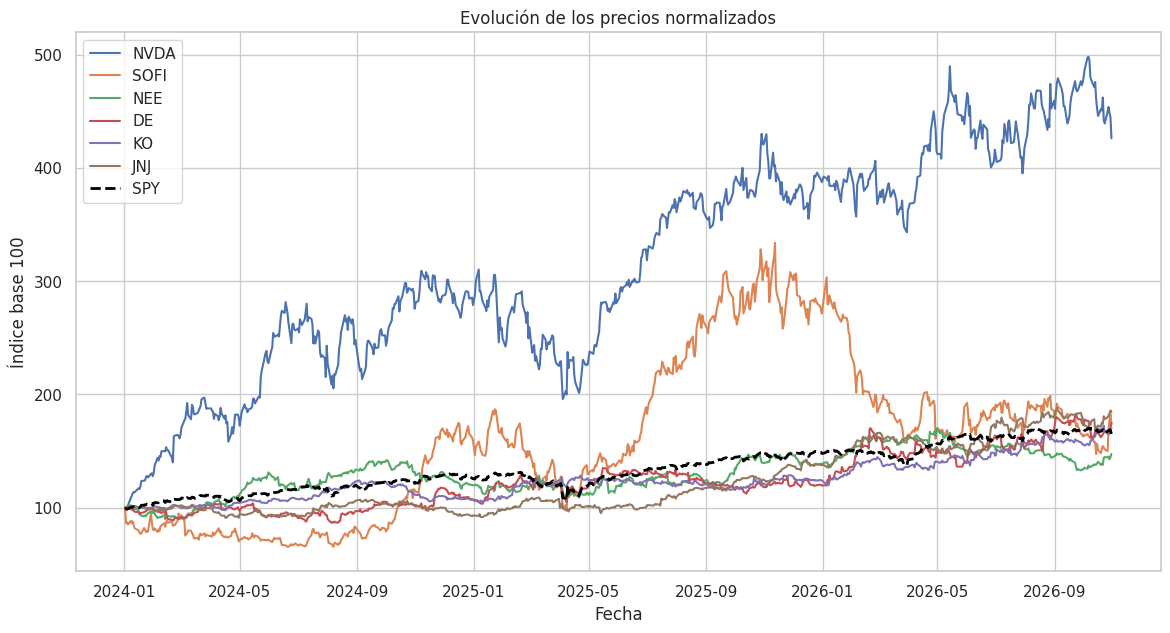

In [6]:
# 6. Evolución de los precios

cierre_norm = cierre.div(cierre.iloc[0]).mul(100)

bench_norm = (
    cierre_bench / cierre_bench.iloc[0]
) * 100

plt.figure(figsize=(14, 7))

for activo in activos:
    plt.plot(
        cierre_norm.index,
        cierre_norm[activo],
        label=activo
    )

plt.plot(
    bench_norm.index,
    bench_norm,
    label="SPY",
    color="black",
    linewidth=2,
    linestyle="--"
)

plt.title("Evolución de los precios normalizados")
plt.xlabel("Fecha")
plt.ylabel("Índice base 100")
plt.legend()
plt.grid(True)
plt.show()

In [7]:
# 7. Calcular los rendimientos

# Rendimientos simples
rend_simple = cierre.pct_change().dropna()

# Rendimientos logarítmicos
rendimientos = np.log(
    cierre / cierre.shift(1)
).dropna()

display(rendimientos.head())

Ticker,NVDA,SOFI,NEE,DE,KO,JNJ
Date,,,,,,
2024-01-03,-0.0125,-0.1495,0.0068,-0.0190,0.0023,0.0062
2024-01-04,0.0090,0.0132,-0.0031,-0.0024,-0.0033,-0.0021
2024-01-05,0.0226,-0.0240,0.0045,0.0091,-0.0015,0.0031
2024-01-08,0.0623,0.0370,0.0134,0.0051,0.0073,0.0025
2024-01-09,0.0168,-0.0249,-0.0146,-0.0120,-0.0018,0.0006


In [8]:
# 8. Calcular el rendimiento del portafolio y del benchmark

# Rendimiento simple ponderado del portafolio
rend_port_simple = (
    rend_simple * pesos
).sum(axis=1)

# Rendimiento logarítmico del portafolio
rend_port = np.log1p(rend_port_simple)

rend_port.name = "Portafolio"

# Rendimiento logarítmico del benchmark
rend_bench = np.log(
    cierre_bench / cierre_bench.shift(1)
).dropna()

rend_bench.name = benchmark

# Unir todos los rendimientos
rend_todos = pd.concat(
    [rendimientos, rend_port, rend_bench],
    axis=1
).dropna()

display(rend_todos.tail())

# Verificaciones
assert len(rend_port) == len(rendimientos)
assert not rend_port.isna().any()

assert np.isclose(
    rend_port_simple.iloc[0],
    (rend_simple.iloc[0] * pesos).sum()
)

print("Rendimientos del portafolio calculados correctamente")

,NVDA,SOFI,NEE,DE,KO,JNJ,Portafolio,SPY
Date,,,,,,,,
2026-10-26,0.0236,-0.0107,-0.0007,-0.0076,-0.0001,0.0094,0.0024,0.0071
2026-10-27,0.0089,0.1259,0.0046,-0.0026,-0.0165,0.0091,0.0227,0.0056
2026-10-28,-0.0118,0.0441,-0.0171,0.0017,0.0060,0.0086,0.0054,0.0034
2026-10-29,-0.0080,0.0271,0.0137,0.0297,0.0118,0.0152,0.0150,-0.0038
2026-10-30,-0.0431,-0.0495,0.0189,0.0232,0.0135,-0.0073,-0.0070,-0.0179


Rendimientos del portafolio calculados correctamente


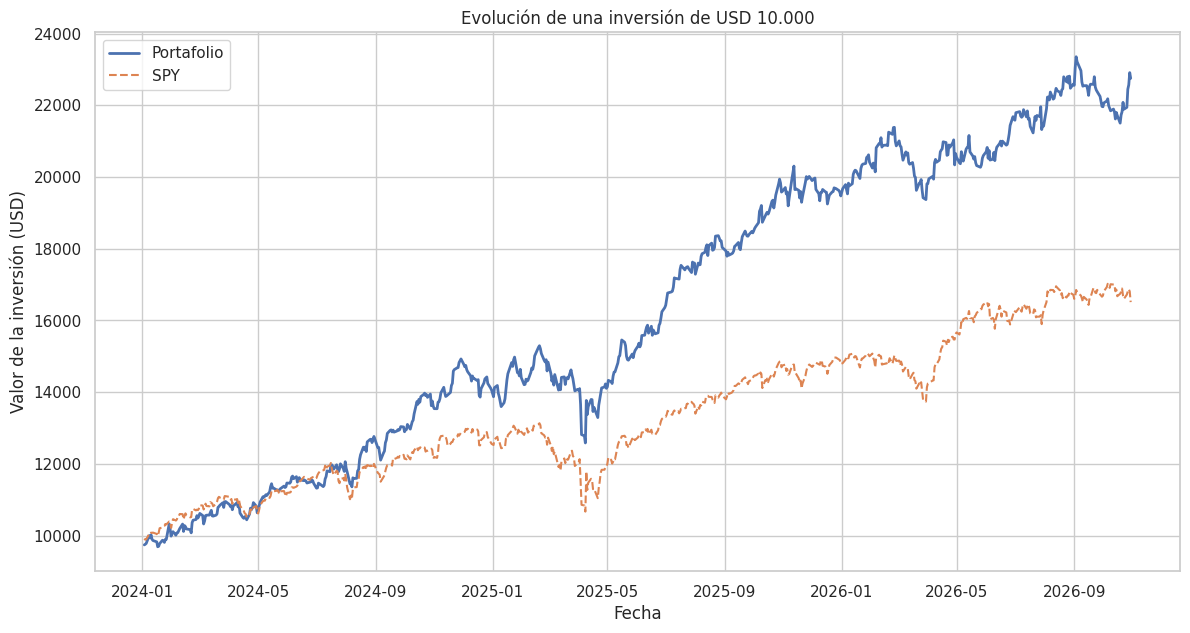

Valor final del portafolio: USD 22,753.19
Valor final del SPY: USD 16,512.24


In [9]:
# 9. Calcular el valor de la inversión

# Valor acumulado del portafolio
valor_port = monto_inicial * np.exp(
    rend_port.cumsum()
)

# Valor acumulado del benchmark
valor_bench = monto_inicial * np.exp(
    rend_bench.cumsum()
)

plt.figure(figsize=(14, 7))

plt.plot(
    valor_port.index,
    valor_port,
    label="Portafolio",
    linewidth=2
)

plt.plot(
    valor_bench.index,
    valor_bench,
    label="SPY",
    linestyle="--"
)

plt.title("Evolución de una inversión de USD 10.000")
plt.xlabel("Fecha")
plt.ylabel("Valor de la inversión (USD)")
plt.legend()
plt.grid(True)
plt.show()

print(f"Valor final del portafolio: USD {valor_port.iloc[-1]:,.2f}")
print(f"Valor final del SPY: USD {valor_bench.iloc[-1]:,.2f}")

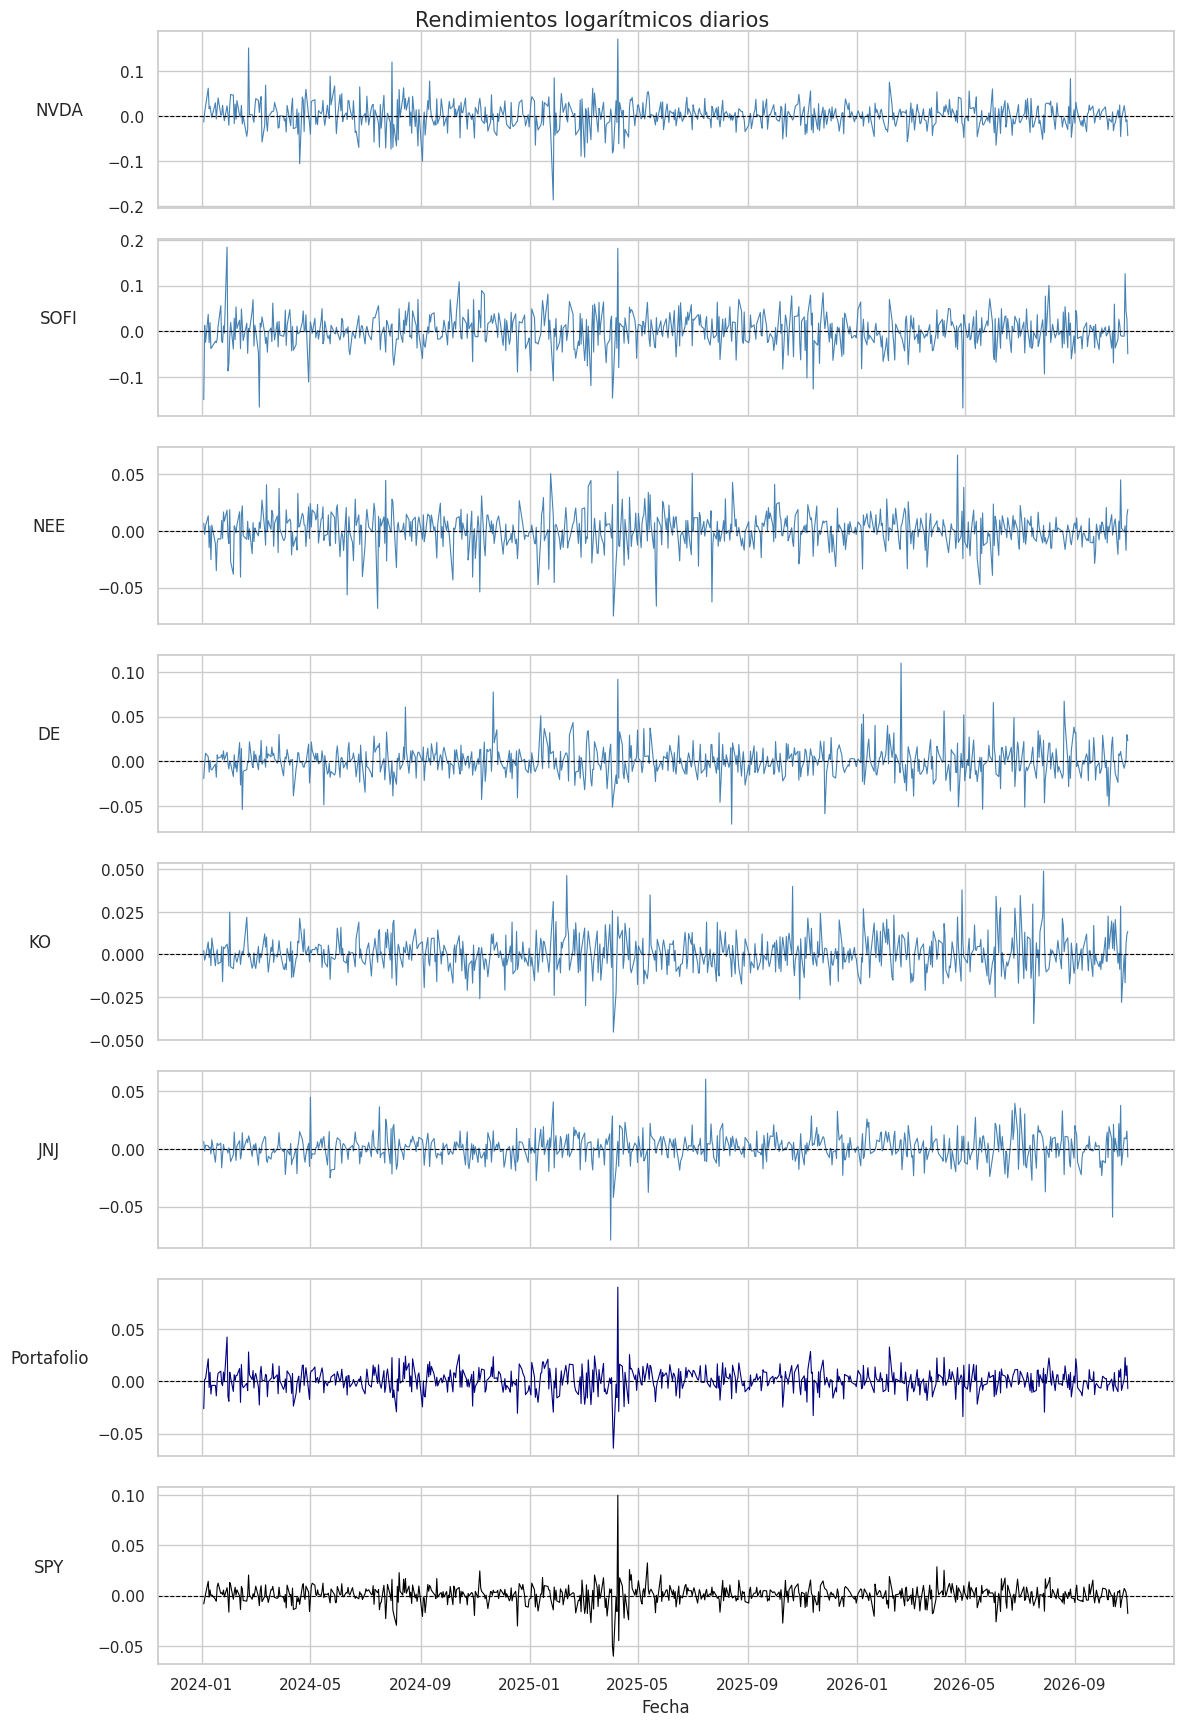

In [10]:
# 10. Análisis exploratorio de los rendimientos

series = list(rend_todos.columns)

fig, axes = plt.subplots(
    nrows=len(series),
    ncols=1,
    figsize=(12, 2.2 * len(series)),
    sharex=True
)

axes = np.atleast_1d(axes)

for ax, nombre in zip(axes, series):

    color = (
        "navy" if nombre == "Portafolio"
        else ("black" if nombre == benchmark else "steelblue")
    )

    ax.plot(
        rend_todos.index,
        rend_todos[nombre],
        color=color,
        linewidth=0.8
    )

    ax.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=0.8
    )

    ax.set_ylabel(nombre, rotation=0, labelpad=35)

axes[-1].set_xlabel("Fecha")

fig.suptitle(
    "Rendimientos logarítmicos diarios",
    fontsize=15
)

plt.tight_layout()
plt.show()

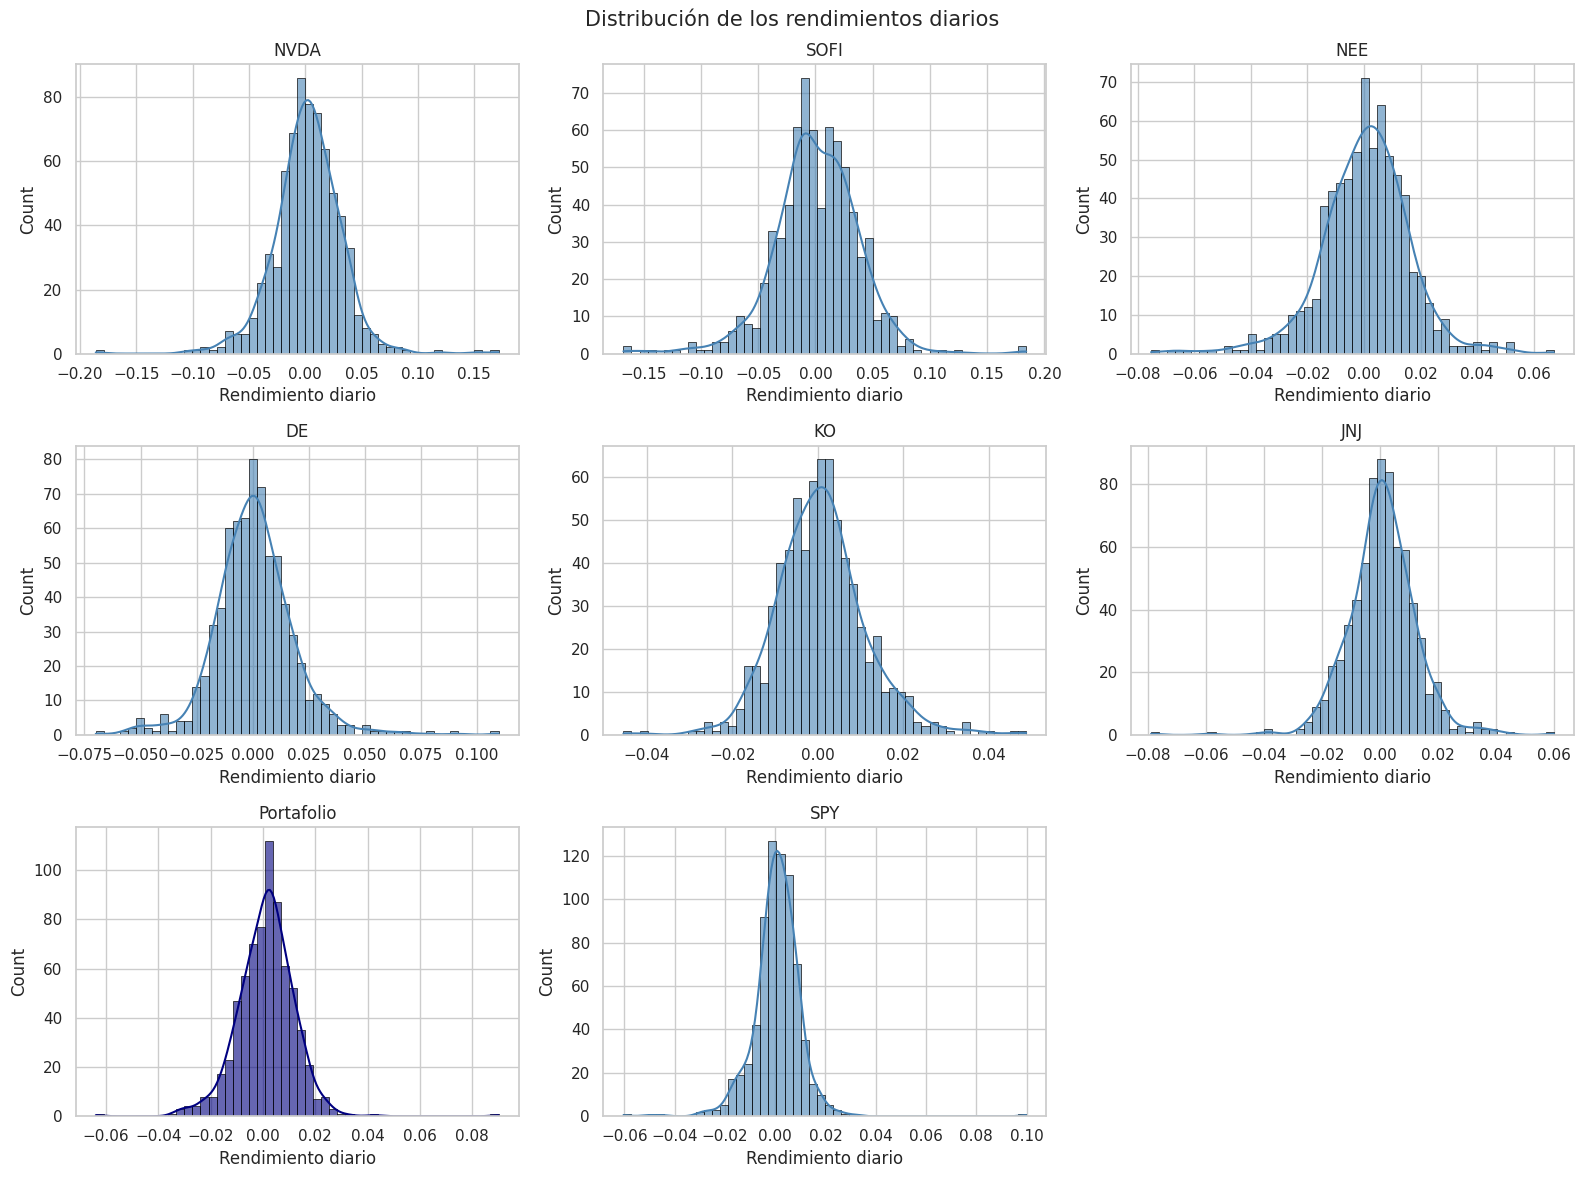

In [11]:
# 11. Distribución de los rendimientos

n_cols = 3
n_rows = math.ceil(len(series) / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, 4 * n_rows)
)

axes = np.array(axes).flatten()

for i, nombre in enumerate(series):

    sns.histplot(
        data=rend_todos,
        x=nombre,
        bins=50,
        kde=True,
        ax=axes[i],
        color="navy" if nombre == "Portafolio" else "steelblue",
        edgecolor="black",
        alpha=0.6
    )

    axes[i].set_title(nombre)
    axes[i].set_xlabel("Rendimiento diario")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(
    "Distribución de los rendimientos diarios",
    fontsize=15
)

plt.tight_layout()
plt.show()

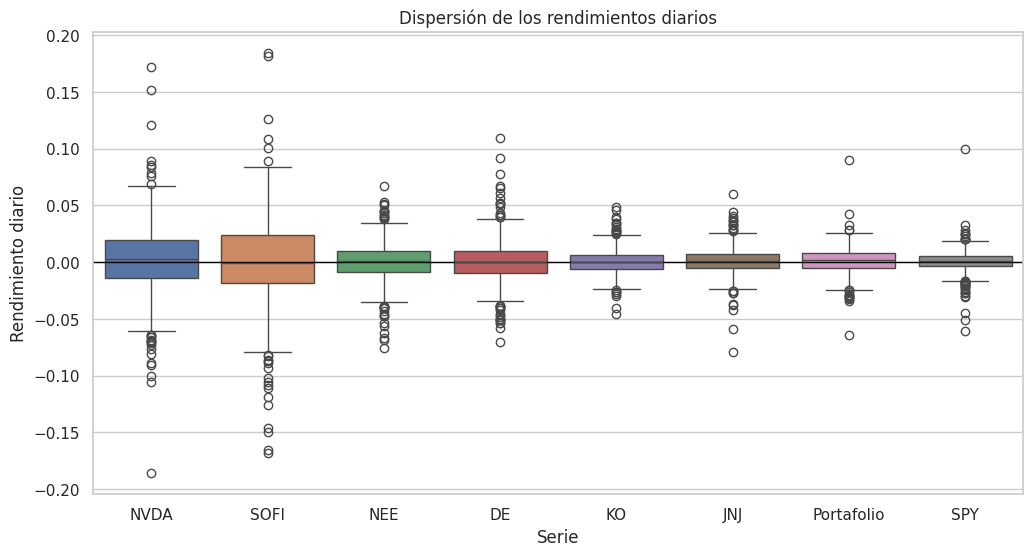

In [12]:
# 12. Comparar la dispersión mediante un boxplot

plt.figure(figsize=(12, 6))

sns.boxplot(data=rend_todos)

plt.axhline(0, color="black", linewidth=1)

plt.title("Dispersión de los rendimientos diarios")
plt.xlabel("Serie")
plt.ylabel("Rendimiento diario")

plt.show()

In [13]:
# 13. Estadísticas descriptivas y riesgo-rendimiento

DIAS_ANIO = 252

resumen = pd.DataFrame({
    "Media diaria": rend_todos.mean(),
    "Mediana": rend_todos.median(),
    "Desv. estándar diaria": rend_todos.std(),
    "Mínimo": rend_todos.min(),
    "Máximo": rend_todos.max()
})

resumen["Rend. anualizado"] = (
    resumen["Media diaria"] * DIAS_ANIO
)

resumen["Volatilidad anualizada"] = (
    resumen["Desv. estándar diaria"] * np.sqrt(DIAS_ANIO)
)

display(resumen.style.format("{:.2%}"))

,Media diaria,Mediana,Desv. estándar diaria,Mínimo,Máximo,Rend. anualizado,Volatilidad anualizada
NVDA,0.20%,0.26%,2.99%,-18.59%,17.16%,51.45%,47.40%
SOFI,0.08%,-0.03%,3.73%,-16.77%,18.41%,19.59%,59.15%
NEE,0.05%,0.11%,1.59%,-7.53%,6.71%,13.78%,25.31%
DE,0.08%,0.04%,1.79%,-7.00%,10.96%,19.81%,28.44%
KO,0.07%,0.04%,1.05%,-4.54%,4.88%,18.85%,16.69%
JNJ,0.09%,0.08%,1.18%,-7.90%,6.01%,21.74%,18.73%
Portafolio,0.12%,0.17%,1.10%,-6.39%,9.00%,29.18%,17.51%
SPY,0.07%,0.10%,0.97%,-6.03%,9.99%,17.80%,15.38%


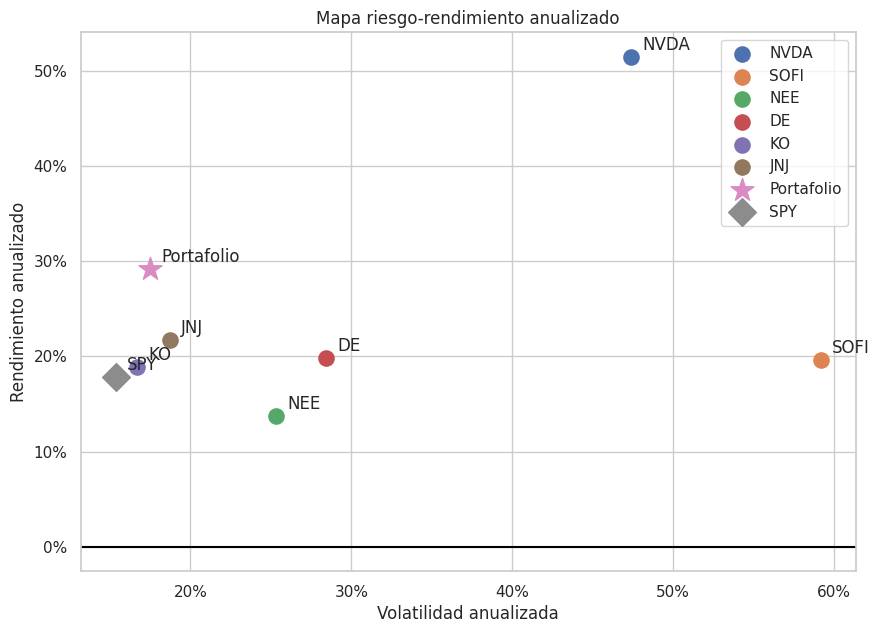

In [14]:
# Gráfico de riesgo y rendimiento

fig, ax = plt.subplots(figsize=(10, 7))

for nombre in resumen.index:

    x = resumen.loc[nombre, "Volatilidad anualizada"]
    y = resumen.loc[nombre, "Rend. anualizado"]

    if nombre == "Portafolio":
        ax.scatter(x, y, s=300, marker="*", label=nombre)

    elif nombre == benchmark:
        ax.scatter(x, y, s=200, marker="D", label=nombre)

    else:
        ax.scatter(x, y, s=120, label=nombre)

    ax.annotate(
        nombre,
        (x, y),
        xytext=(8, 5),
        textcoords="offset points"
    )

ax.axhline(0, color="black")

ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda v, _: f"{v:.0%}")
)

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda v, _: f"{v:.0%}")
)

ax.set_title("Mapa riesgo-rendimiento anualizado")
ax.set_xlabel("Volatilidad anualizada")
ax.set_ylabel("Rendimiento anualizado")

ax.legend()
plt.show()

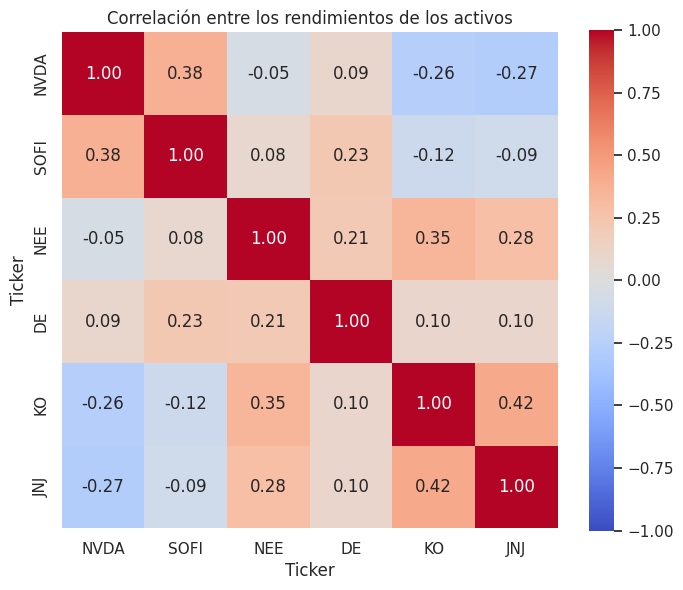

Correlación promedio: 0.10


In [15]:
# 14. Correlación entre los activos

correlacion = rendimientos[activos].corr()

plt.figure(figsize=(8, 6.5))

sns.heatmap(
    correlacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Correlación entre los rendimientos de los activos")
plt.show()

corr_promedio = correlacion.values[
    np.triu_indices_from(correlacion, k=1)
].mean()

print(f"Correlación promedio: {corr_promedio:.2f}")

In [16]:
# 15. Beneficio de la diversificación

vol_activos = (
    rendimientos[activos].std() * np.sqrt(DIAS_ANIO)
)

vol_sin_diversificar = (
    vol_activos * pesos
).sum()

vol_portafolio = (
    rend_port.std() * np.sqrt(DIAS_ANIO)
)

beneficio_div = (
    vol_sin_diversificar - vol_portafolio
)

print(
    f"Volatilidad sin diversificar: "
    f"{vol_sin_diversificar:.2%}"
)

print(
    f"Volatilidad del portafolio: "
    f"{vol_portafolio:.2%}"
)

print(
    f"Beneficio de diversificación: "
    f"{beneficio_div:.2%}"
)

if vol_sin_diversificar != 0:
    print(
        f"Reducción relativa del riesgo: "
        f"{beneficio_div / vol_sin_diversificar:.2%}"
    )

Volatilidad sin diversificar: 32.62%
Volatilidad del portafolio: 17.51%
Beneficio de diversificación: 15.11%
Reducción relativa del riesgo: 46.32%


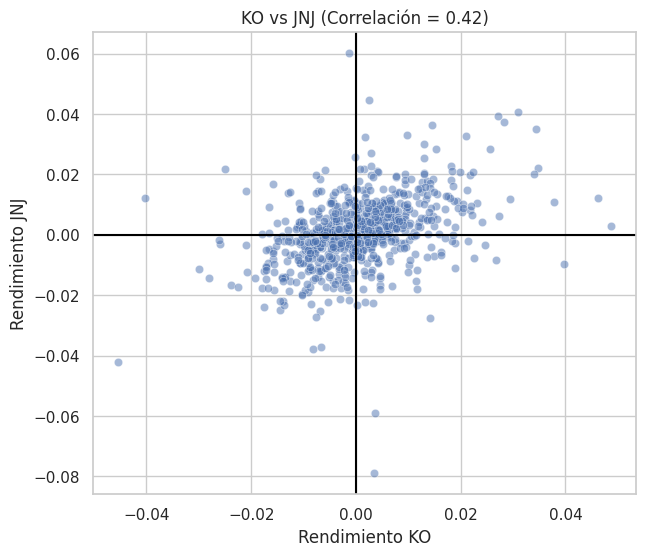

In [17]:
# 16. Analizar la pareja de activos más correlacionada

corr_sin_diag = correlacion.where(
    ~np.eye(len(correlacion), dtype=bool)
)

a1, a2 = corr_sin_diag.stack().idxmax()

plt.figure(figsize=(7, 6))

sns.scatterplot(
    data=rendimientos,
    x=a1,
    y=a2,
    alpha=0.5
)

plt.axhline(0, color="black")
plt.axvline(0, color="black")

plt.title(
    f"{a1} vs {a2} "
    f"(Correlación = {correlacion.loc[a1, a2]:.2f})"
)

plt.xlabel(f"Rendimiento {a1}")
plt.ylabel(f"Rendimiento {a2}")

plt.show()

In [18]:
# 17. Probabilidad empírica del portafolio

umbral_perdida = -0.02
umbral_ganancia = 0.02

total_dias = len(rend_port)

prob_perdida_emp = (
    rend_port <= umbral_perdida
).mean()

prob_ganancia_emp = (
    rend_port > umbral_ganancia
).mean()

q05_emp = rend_port.quantile(0.05)
q01_emp = rend_port.quantile(0.01)

intervalo_95_emp = (
    rend_port.quantile(0.025),
    rend_port.quantile(0.975)
)

print(f"Días analizados: {total_dias}")

print(
    f"Probabilidad de perder 2% o más: "
    f"{prob_perdida_emp:.2%}"
)

print(
    f"Probabilidad de ganar más del 2%: "
    f"{prob_ganancia_emp:.2%}"
)

print(f"VaR histórico 95%: {q05_emp:.2%}")
print(f"VaR histórico 99%: {q01_emp:.2%}")

print(
    f"Intervalo empírico del 95%: "
    f"[{intervalo_95_emp[0]:.2%}, {intervalo_95_emp[1]:.2%}]"
)

Días analizados: 710
Probabilidad de perder 2% o más: 3.24%
Probabilidad de ganar más del 2%: 3.10%
VaR histórico 95%: -1.58%
VaR histórico 99%: -2.91%
Intervalo empírico del 95%: [-2.19%, 2.15%]


Media diaria: 0.00116
Desviación estándar diaria: 0.01103


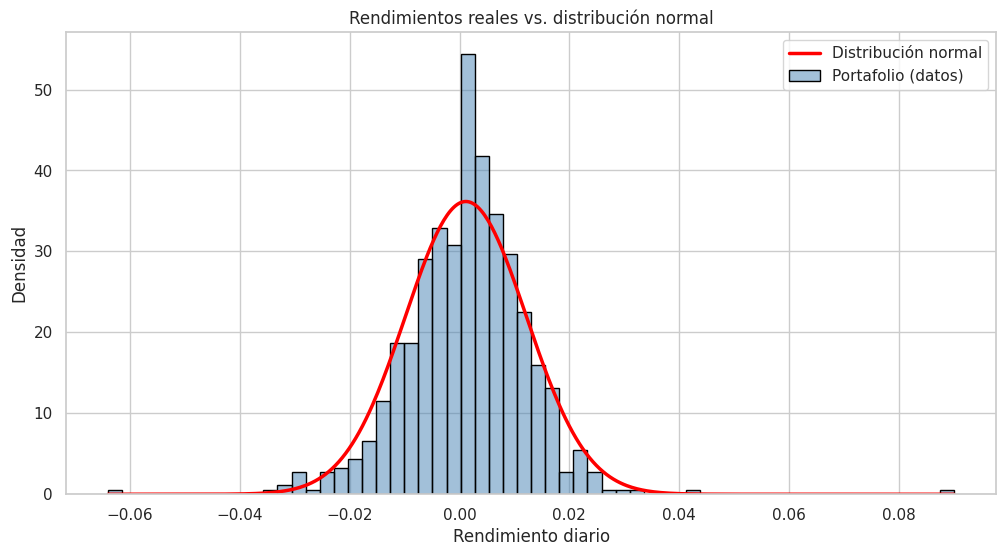

In [19]:
# 18. Comparar los rendimientos con una distribución normal

mu_p = rend_port.mean()
sigma_p = rend_port.std()

print(f"Media diaria: {mu_p:.5f}")
print(f"Desviación estándar diaria: {sigma_p:.5f}")

fig, ax = plt.subplots(figsize=(12, 6))

sns.histplot(
    rend_port,
    bins=60,
    stat="density",
    color="steelblue",
    alpha=0.5,
    edgecolor="black",
    label="Portafolio (datos)",
    ax=ax
)

x = np.linspace(
    rend_port.min(),
    rend_port.max(),
    500
)

ax.plot(
    x,
    norm.pdf(x, loc=mu_p, scale=sigma_p),
    color="red",
    linewidth=2.5,
    label="Distribución normal"
)

ax.set_title("Rendimientos reales vs. distribución normal")
ax.set_xlabel("Rendimiento diario")
ax.set_ylabel("Densidad")
ax.legend()

plt.show()

In [20]:
# 19. Función para graficar probabilidades normales

def graficar_area_normal(
    mu=0,
    sigma=1,
    a=None,
    b=None,
    ax=None
):

    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 5))

    x = np.linspace(
        mu - 4 * sigma,
        mu + 4 * sigma,
        1000
    )

    y = norm.pdf(x, loc=mu, scale=sigma)

    ax.plot(
        x,
        y,
        color="navy",
        linewidth=2,
        label=f"N(μ={mu:.4g}, σ={sigma:.4g})"
    )

    li = -np.inf if a is None else a
    ls = np.inf if b is None else b

    ax.fill_between(
        x,
        y,
        where=(x >= li) & (x <= ls),
        color="tomato",
        alpha=0.5
    )

    prob = (
        norm.cdf(ls, loc=mu, scale=sigma)
        - norm.cdf(li, loc=mu, scale=sigma)
    )

    if a is None:
        etiqueta = f"P(X ≤ {b:g}) = {prob:.4f}"

    elif b is None:
        etiqueta = f"P(X ≥ {a:g}) = {prob:.4f}"

    else:
        etiqueta = (
            f"P({a:g} ≤ X ≤ {b:g}) = {prob:.4f}"
        )

    for lim in [a, b]:
        if lim is not None:
            ax.axvline(
                lim,
                color="tomato",
                linestyle="--",
                linewidth=1.5
            )

    ax.set_title(etiqueta)
    ax.set_ylim(bottom=0)
    ax.legend(loc="upper right")

    return prob

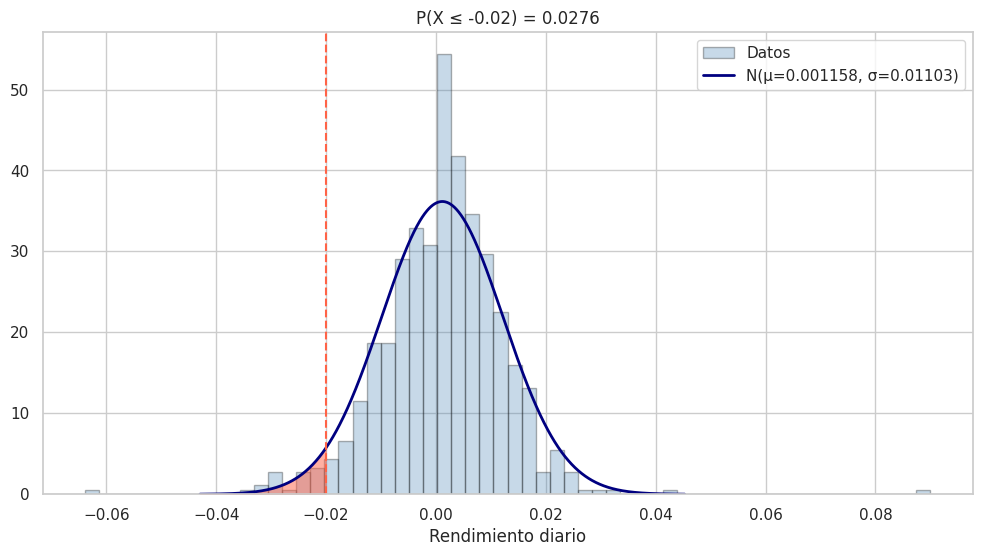

Probabilidad normal de perder 2% o más: 2.76%
Probabilidad empírica de perder 2% o más: 3.24%


In [21]:
# 20. Probabilidad de pérdida según la distribución normal

fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(
    rend_port,
    bins=60,
    density=True,
    color="steelblue",
    alpha=0.3,
    edgecolor="black",
    label="Datos"
)

prob_perdida_norm = graficar_area_normal(
    mu=mu_p,
    sigma=sigma_p,
    b=umbral_perdida,
    ax=ax
)

ax.set_xlabel("Rendimiento diario")

plt.show()

print(
    f"Probabilidad normal de perder 2% o más: "
    f"{prob_perdida_norm:.2%}"
)

print(
    f"Probabilidad empírica de perder 2% o más: "
    f"{prob_perdida_emp:.2%}"
)

In [22]:
# 21. Comparación de probabilidades y cuantiles

# Umbrales de pérdida
umbrales = [-0.01, -0.02, -0.03, -0.04]

tabla_prob = pd.DataFrame({
    "Umbral": umbrales,

    "Prob. normal": [
        norm.cdf(u, loc=mu_p, scale=sigma_p)
        for u in umbrales
    ],

    "Prob. empírica": [
        (rend_port <= u).mean()
        for u in umbrales
    ]
})

tabla_prob["Empírica / Normal"] = (
    tabla_prob["Prob. empírica"]
    / tabla_prob["Prob. normal"]
)

# Cuantiles
niveles = [0.01, 0.025, 0.05]

tabla_cuant = pd.DataFrame({
    "Nivel": niveles,

    "Cuantil normal": [
        norm.ppf(q, loc=mu_p, scale=sigma_p)
        for q in niveles
    ],

    "Cuantil empírico": [
        rend_port.quantile(q)
        for q in niveles
    ]
})

display(
    tabla_prob.style.format({
        "Umbral": "{:.0%}",
        "Prob. normal": "{:.2%}",
        "Prob. empírica": "{:.2%}",
        "Empírica / Normal": "{:.2f}"
    })
)

display(
    tabla_cuant.style.format({
        "Nivel": "{:.1%}",
        "Cuantil normal": "{:.2%}",
        "Cuantil empírico": "{:.2%}"
    })
)

,Umbral,Prob. normal,Prob. empírica,Empírica / Normal
0,-1%,15.59%,13.52%,0.87
1,-2%,2.76%,3.24%,1.18
2,-3%,0.24%,0.70%,2.97
3,-4%,0.01%,0.14%,14.77


,Nivel,Cuantil normal,Cuantil empírico
0,1.0%,-2.45%,-2.91%
1,2.5%,-2.05%,-2.19%
2,5.0%,-1.70%,-1.58%


Asimetría: 0.258
Exceso de curtosis: 7.473
Jarque-Bera: estadístico = 1660.13, p-valor = 0


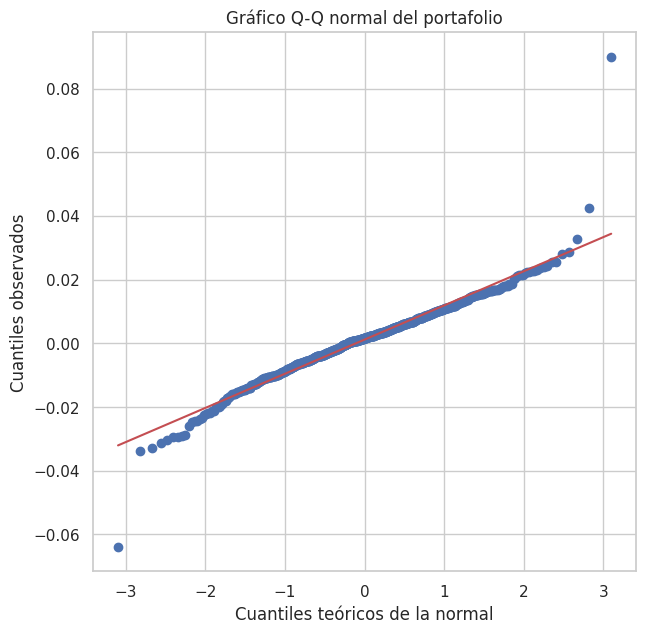

In [23]:
# 22. Asimetría, curtosis y prueba Jarque-Bera

asimetria_p = stats.skew(rend_port)

# Exceso de curtosis: para una normal es igual a cero
curtosis_p = stats.kurtosis(rend_port)

# Prueba de normalidad Jarque-Bera
jb_p = stats.jarque_bera(rend_port)

print(f"Asimetría: {asimetria_p:.3f}")

print(f"Exceso de curtosis: {curtosis_p:.3f}")

print(
    f"Jarque-Bera: estadístico = {jb_p.statistic:.2f}, "
    f"p-valor = {jb_p.pvalue:.4g}"
)

# Gráfico Q-Q
fig, ax = plt.subplots(figsize=(7, 7))

stats.probplot(
    rend_port,
    dist="norm",
    plot=ax
)

ax.set_title("Gráfico Q-Q normal del portafolio")
ax.set_xlabel("Cuantiles teóricos de la normal")
ax.set_ylabel("Cuantiles observados")

plt.show()

In [24]:
# 23. Valor en riesgo (VaR) en dinero

# Valor actual del portafolio
valor_actual = valor_port.iloc[-1]


def var_dinero(cuantil_log, valor):

    # La pérdida monetaria se expresa como valor positivo
    return valor * (1 - np.exp(cuantil_log))


# Comparar VaR normal e histórico
var_tabla = pd.DataFrame({

    "VaR normal (%)": [
        norm.ppf(0.05, mu_p, sigma_p),
        norm.ppf(0.01, mu_p, sigma_p)
    ],

    "VaR histórico (%)": [
        q05_emp,
        q01_emp
    ]

}, index=["95%", "99%"])


var_tabla["VaR normal ($)"] = var_dinero(
    var_tabla["VaR normal (%)"],
    valor_actual
)

var_tabla["VaR histórico ($)"] = var_dinero(
    var_tabla["VaR histórico (%)"],
    valor_actual
)


print(
    f"Valor actual del portafolio: "
    f"USD {valor_actual:,.2f}"
)

display(
    var_tabla.style.format({
        "VaR normal (%)": "{:.2%}",
        "VaR histórico (%)": "{:.2%}",
        "VaR normal ($)": "${:,.2f}",
        "VaR histórico ($)": "${:,.2f}"
    })
)

Valor actual del portafolio: USD 22,753.19


,VaR normal (%),VaR histórico (%),VaR normal ($),VaR histórico ($)
95%,-1.70%,-1.58%,$383.24,$357.46
99%,-2.45%,-2.91%,$550.78,$653.31


In [25]:
# 24. Ficha técnica del portafolio

# Tasa libre de riesgo: supuesto académico anual del 4%
tasa_libre_riesgo = 0.04


def max_drawdown(valor):

    maximo_previo = valor.cummax()

    drawdown = (
        valor / maximo_previo
    ) - 1

    return drawdown.min()


def ficha(r, valor):

    mu_a = r.mean() * DIAS_ANIO

    sigma_a = (
        r.std() * np.sqrt(DIAS_ANIO)
    )

    return {

        "Rendimiento total":
            valor.iloc[-1] / valor.iloc[0] - 1,

        "Rendimiento anualizado":
            mu_a,

        "Volatilidad anualizada":
            sigma_a,

        "Sharpe":
            (mu_a - tasa_libre_riesgo) / sigma_a,

        "Máxima caída":
            max_drawdown(valor),

        "VaR 95% diario (histórico)":
            r.quantile(0.05),

        "Peor día":
            r.min(),

        "Mejor día":
            r.max(),

        "Asimetría":
            stats.skew(r),

        "Exceso de curtosis":
            stats.kurtosis(r)
    }


# Incluir el capital inicial en la serie de valores
valor_port_c = pd.concat([
    pd.Series(
        [monto_inicial],
        index=[cierre.index[0]]
    ),
    valor_port
])

valor_bench_c = pd.concat([
    pd.Series(
        [monto_inicial],
        index=[cierre.index[0]]
    ),
    valor_bench
])


# Construir la ficha técnica
ficha_tecnica = pd.DataFrame({

    "Portafolio": ficha(
        rend_port,
        valor_port_c
    ),

    benchmark: ficha(
        rend_bench,
        valor_bench_c
    )

})


formatos = {
    k: "{:.2%}"
    for k in ficha_tecnica.index
}

formatos.update({
    "Sharpe": "{:.2f}",
    "Asimetría": "{:.2f}",
    "Exceso de curtosis": "{:.2f}"
})


display(
    ficha_tecnica.style.format(formatos)
)

,Portafolio,SPY
Rendimiento total,1.275319,0.651224
Rendimiento anualizado,0.291795,0.178003
Volatilidad anualizada,0.175116,0.153792
Sharpe,1.437871,0.897336
Máxima caída,-0.177240,-0.187552
VaR 95% diario (histórico),-0.015835,-0.014999
Peor día,-0.063922,-0.060327
Mejor día,0.089995,0.099863
Asimetría,0.257611,0.641432
Exceso de curtosis,7.473405,18.819194


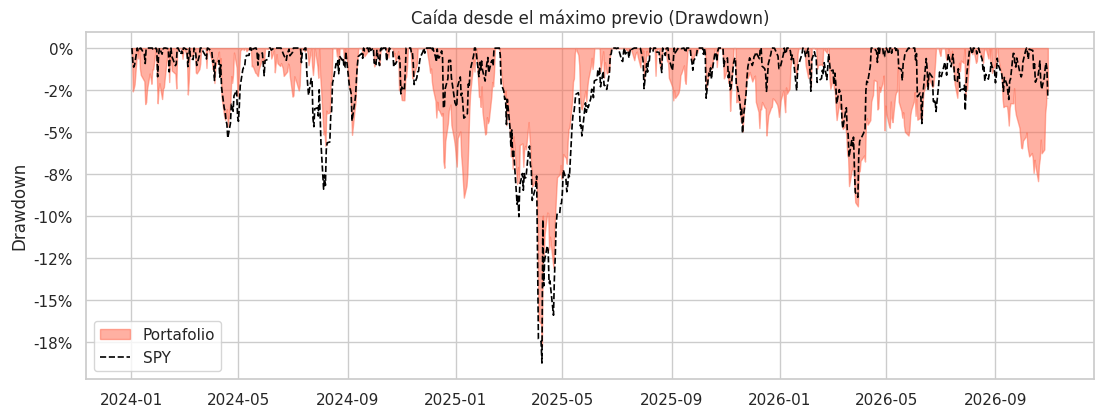

In [26]:
# 25. Gráfico de drawdown

#El drawdown permite observar cuánto ha caído el portafolio desde su máximo histórico.

dd_port = (
    valor_port_c / valor_port_c.cummax()
) - 1

dd_bench = (
    valor_bench_c / valor_bench_c.cummax()
) - 1


fig, ax = plt.subplots(figsize=(13, 4.5))

ax.fill_between(
    dd_port.index,
    dd_port,
    0,
    color="tomato",
    alpha=0.5,
    label="Portafolio"
)

ax.plot(
    dd_bench.index,
    dd_bench,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label=benchmark
)

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda v, _: f"{v:.0%}")
)

ax.set_title("Caída desde el máximo previo (Drawdown)")
ax.set_ylabel("Drawdown")

ax.legend(loc="lower left")

plt.show()

